In [2]:
from google.colab import files
uploaded = files.upload()

Saving salesdaily.csv to salesdaily.csv
Saving saleshourly.csv to saleshourly.csv
Saving salesmonthly.csv to salesmonthly.csv
Saving salesweekly.csv to salesweekly.csv


In [4]:
import pandas as pd
df= pd.read_csv('salesdaily.csv')

df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,1/3/2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,1/4/2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,1/5/2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,1/6/2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


In [ ]:
df.info()

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum         2106 non-null   object 
 1   M01AB         2106 non-null   float64
 2   M01AE         2106 non-null   float64
 3   N02BA         2106 non-null   float64
 4   N02BE         2106 non-null   float64
 5   N05B          2106 non-null   float64
 6   N05C          2106 non-null   float64
 7   R03           2106 non-null   float64
 8   R06           2106 non-null   float64
 9   Year          2106 non-null   int64  
 10  Month         2106 non-null   int64  
 11  Hour          2106 non-null   int64  
 12  Weekday Name  2106 non-null   object 
dtypes: float64(8), int64(3), object(2)
memory usage: 214.0+ KB


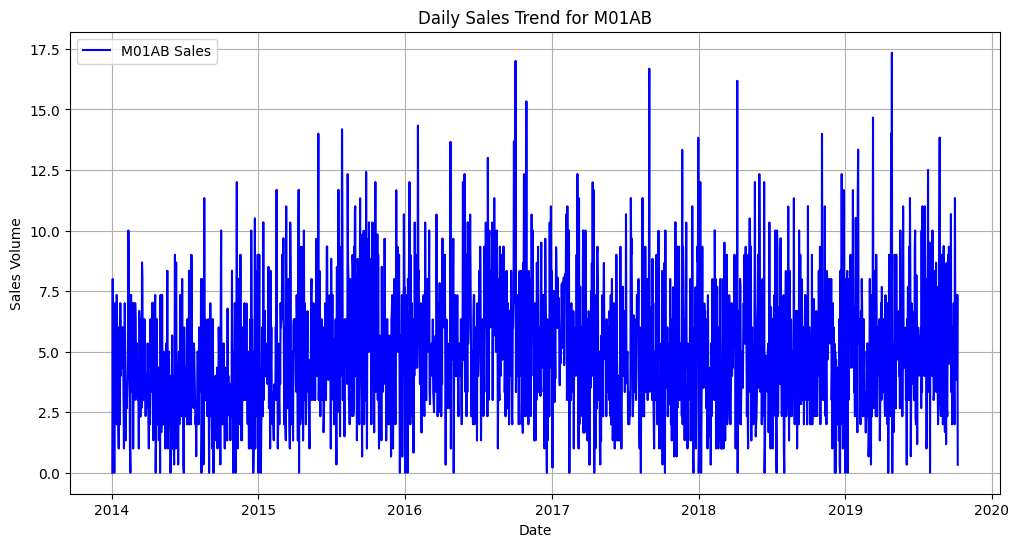

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df_daily = pd.read_csv('salesdaily.csv')


df_daily['datum'] = pd.to_datetime(df_daily['datum'])

df_daily = df_daily.sort_values('datum')

plt.figure(figsize=(12, 6))
plt.plot(df_daily['datum'], df_daily['M01AB'], label='M01AB Sales', color='blue')
plt.title('Daily Sales Trend for M01AB')
plt.xlabel('Date')
plt.ylabel('Sales Volume')
plt.legend()
plt.grid(True)
plt.show()

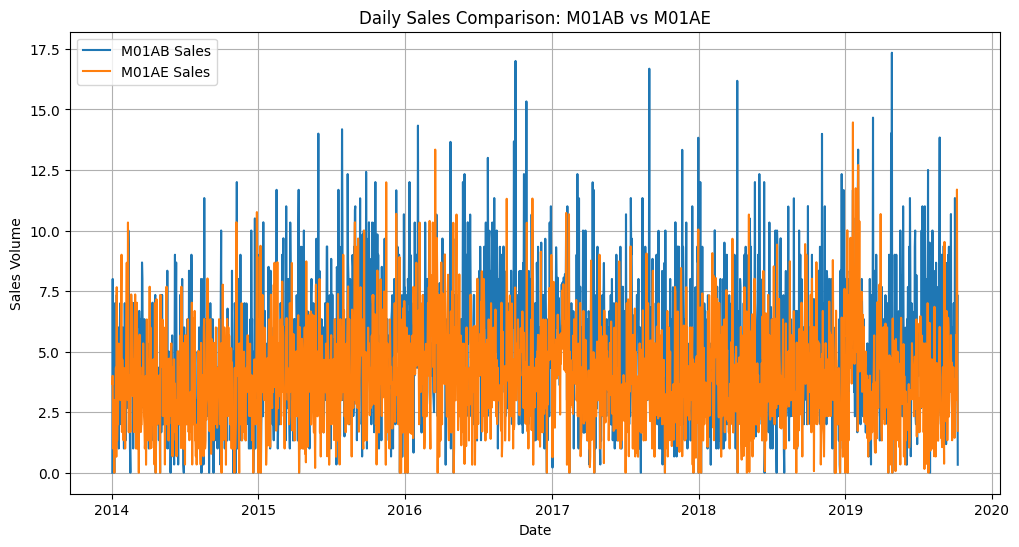

In [7]:
import matplotlib.pyplot as plt

df['datum'] = pd.to_datetime (df['datum'])

df = df.sort_values('datum')

plt.figure(figsize=(12, 6))
plt.plot(df['datum'], df['M01AB'], label='M01AB Sales')
plt.plot(df['datum'], df['M01AE'], label='M01AE Sales')
plt.title('Daily Sales Comparison: M01AB vs M01AE')
plt.xlabel('Date')
plt.ylabel('Sales Volume')
plt.legend()
plt.grid(True)
plt.show()

In [8]:
df[['M01AB', 'M01AE']].sum()


,0
M01AB,10600.937083
M01AE,8204.618646


In [9]:
monthly_m = df.groupby('Month')[['M01AB', 'M01AE']].sum()
print(monthly_m)

             M01AB       M01AE
Month                         
1       929.132083  807.924250
2       844.920000  787.616083
3       913.650000  723.862000
4       921.230000  646.219000
5       901.390000  678.816000
6       848.660000  642.220000
7       968.673333  702.135000
8      1009.670000  674.132000
9       900.880000  714.574000
10      810.485000  633.475312
11      783.846667  571.210000
12      768.400000  622.435000


             M01AB       M01AE
Month                         
1       929.132083  807.924250
2       844.920000  787.616083
3       913.650000  723.862000
4       921.230000  646.219000
5       901.390000  678.816000
6       848.660000  642.220000
7       968.673333  702.135000
8      1009.670000  674.132000
9       900.880000  714.574000
10      810.485000  633.475312
11      783.846667  571.210000
12      768.400000  622.435000


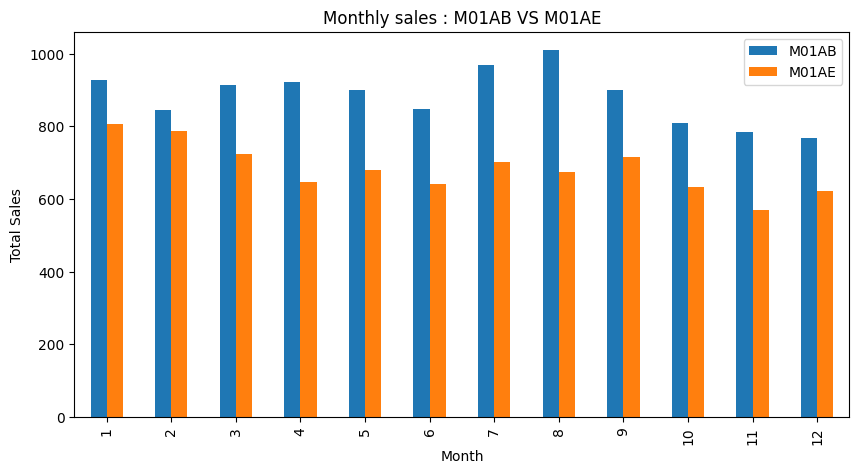

In [10]:
monthly_m.plot(kind='bar', figsize=(10,5))
print(monthly_m)

plt.title('Monthly sales : M01AB VS M01AE')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.legend()
plt.show()

N02BE    63005.402708
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333
dtype: float64


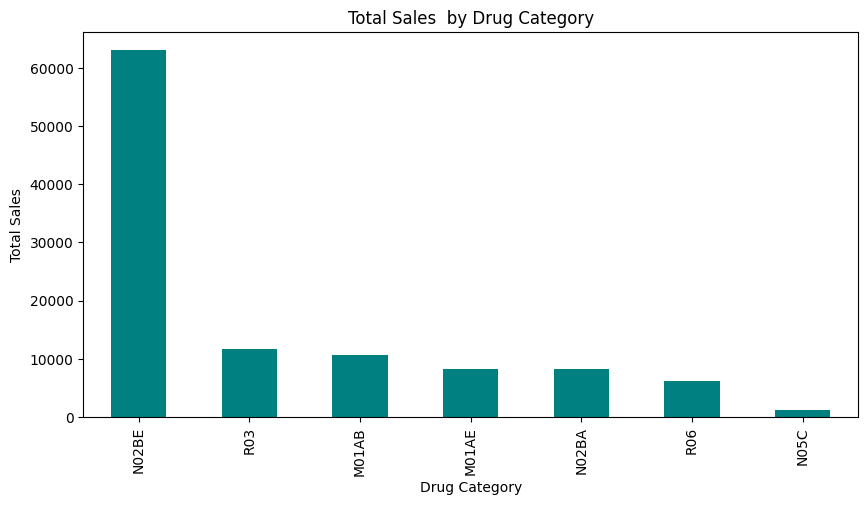

In [15]:
drugs_cols = ["M01AB", "M01AE", "N02BA","N02BE", "N05C", 'R03', 'R06']
total_drugs = df[drugs_cols].sum().sort_values(ascending=False)
print(total_drugs)

total_drugs.plot(kind='bar', figsize=(10,5), color= 'teal')
plt.title('Total Sales  by Drug Category')
plt.xlabel('Drug Categeory')
plt.xlabel('Drug Category')
plt.ylabel('Total Sales')
plt.show()


Month
1     11937.741083
2     10079.376917
3      9826.205000
4      8835.318000
5      8534.167667
6      7568.361000
7      7214.903333
8      7347.611333
9      9337.556667
10    10507.128854
11     8139.016667
12     9622.379667
dtype: float64


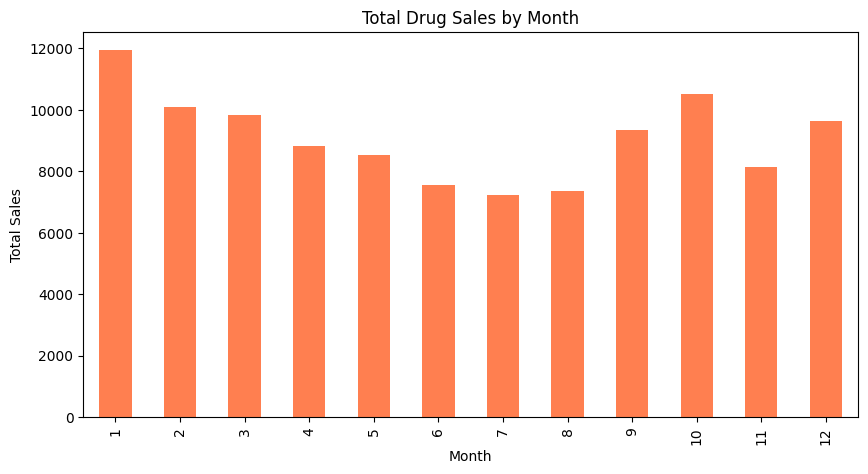

In [16]:
monthly_total = df.groupby('Month')[drugs_cols].sum().sum(axis=1)
print(monthly_total)

monthly_total.plot(kind='bar', figsize=(10, 5), color='coral')
plt.title('Total Drug Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.show()